# Predicting unsolved homicides and detecting serial-offender patterns
61.501 Production Ready Machine Learning - project notebook.

This notebook walks through the full pipeline. All logic lives in `src/homicide/`; the notebook only calls it and shows the results. Every step can also be run from the command line (`make all`, see README).

**Before running:** put `database.csv` in `data/raw/` (see `data/README.md`).

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT / 'src'))
import pandas as pd
from IPython.display import Image, display
from homicide.config import load_config
from homicide import data, train, evaluate, cluster, figures
cfg = load_config(ROOT / 'config.yaml')
FIG = cfg['paths']['figures_dir']
MET = cfg['paths']['metrics_dir']

## 1. Data: load, clean, split by year
Perpetrator fields and `Relationship` are only known for solved cases, so they are dropped (label leakage). We train on 1980-2008, tune on 2009-2011 and test once on 2012-2014.

In [2]:
train_df, val_df, test_df = data.build_splits(cfg, save=True)
pd.DataFrame({s: {'rows': len(d), 'years': f"{d.Year.min()}-{d.Year.max()}", 'unsolved share': round(d.y.mean(), 3)} for s, d in zip(['train', 'validation', 'test'], [train_df, val_df, test_df])}).T

,rows,years,unsolved share
train,548928,1980-2008,0.298
validation,45717,2009-2011,0.292
test,43809,2012-2014,0.302


## 2. Train and tune the classifiers
Majority baseline vs. logistic regression, decision tree, random forest and gradient boosting. Positive class = *unsolved*. Hyper-parameters are chosen on the validation years by average precision. (This cell takes 15-30 minutes; set `RUN_TRAINING = False` to reuse saved models.)

In [3]:
RUN_TRAINING = False
if RUN_TRAINING or not (cfg['paths']['models_dir'] / 'best_model.joblib').exists():
    train.run(cfg)
val_summary = json.load(open(MET / 'validation_summary.json'))
print('selected model:', val_summary['selected_model'])
pd.read_csv(MET / 'tuning_results.csv').sort_values('average_precision', ascending=False).groupby('model').head(1).round(3)

selected model: random_forest


,model,params,average_precision,roc_auc,accuracy,precision,recall,f1,macro_f1,fit_seconds
40,random_forest,"{""n_estimators"": 200, ""max_depth"": null, ""min_...",0.566,0.761,0.754,0.620,0.405,0.489,0.664,35.610
46,hist_gradient_boosting,"{""learning_rate"": 0.05, ""max_leaf_nodes"": 63, ...",0.557,0.760,0.751,0.607,0.420,0.496,0.666,11.577
15,decision_tree,"{""criterion"": ""gini"", ""max_depth"": 20, ""min_sa...",0.528,0.738,0.737,0.574,0.389,0.463,0.645,2.689
44,adaboost,"{""base_max_depth"": 3, ""n_estimators"": 200, ""le...",0.506,0.740,0.730,0.561,0.340,0.423,0.623,84.356
1,logistic_regression,"{""C"": 0.01}",0.482,0.727,0.717,0.533,0.253,0.343,0.581,2.939
0,majority_baseline,{},0.292,0.500,0.708,0.000,0.000,0.000,0.414,0.000


## 3. Evaluate once on the test years

In [4]:
evaluate.run(cfg)
pd.read_csv(MET / 'test_results.csv').round(3)

,model,threshold,average_precision,roc_auc,accuracy,precision,recall,f1,macro_f1,selected
0,majority_baseline,0.500,0.302,0.500,0.698,0.000,0.000,0.000,0.411,False
1,logistic_regression,0.295,0.484,0.719,0.633,0.437,0.740,0.549,0.620,False
2,decision_tree,0.298,0.536,0.723,0.656,0.455,0.693,0.549,0.636,False
3,random_forest,0.342,0.569,0.753,0.698,0.500,0.661,0.569,0.668,True
4,adaboost,0.446,0.526,0.745,0.675,0.475,0.702,0.566,0.653,False
5,hist_gradient_boosting,0.325,0.572,0.759,0.693,0.494,0.688,0.575,0.668,False


## 4. Cluster detector (k-modes) and the Gary, Indiana check

In [5]:
check = cluster.run(cfg)
check

{'applicable': True,
 'unsolved_lake_female_strangulations': 16,
 'in_any_flagged_cluster': 12,
 'cluster_with_most_of_them': 0,
 'of_them_in_that_cluster': 8,
 'cluster_size': 303,
 'cluster_unsolved_share': 0.40264026402640263,
 'regional_unsolved_share': 0.32207973479891827,
 'cluster_p_value': 0.0019120190494504893,
 'cluster_flagged': True,
 'cluster_flagged_bonferroni': False,
 'cluster_profile': {'City': 'Lake',
  'Victim Sex': 'Female',
  'Victim Age Group': '25-34',
  'Victim Race': 'Black',
  'Weapon': 'Blunt Object'},
 'region': 'Indiana',
 'k': 40,
 'n_clusters_flagged': 5,
 'n_clusters_flagged_bonferroni': 3}

In [6]:
pd.read_csv(MET / 'clusters.csv').query('flagged').head(10)

,cluster,n_cases,n_unsolved,unsolved_share,p_value,years,City,City purity,Victim Sex,Victim Sex purity,Victim Age Group,Victim Age Group purity,Victim Race,Victim Race purity,Weapon,Weapon purity,flagged,flagged_bonferroni
0,2,1325,605,0.456604,1.453175e-24,1980-2014,Lake,0.699623,Male,0.938113,18-24,0.803774,Black,0.988679,Handgun,0.723774,True,True
1,26,509,266,0.522593,7.691736e-21,1980-2014,Lake,1.000000,Male,1.000000,25-34,1.000000,Black,0.982318,Handgun,0.860511,True,True
2,3,541,245,0.452865,1.554076e-10,1980-2014,Lake,0.787431,Male,1.000000,35-49,1.000000,Black,0.842884,Handgun,0.752311,True,True
3,0,303,122,0.402640,1.912019e-03,1980-2014,Lake,0.600660,Female,0.851485,25-34,0.448845,Black,0.702970,Blunt Object,0.564356,True,False
4,20,145,63,0.434483,2.980318e-03,1980-2014,Lake,0.648276,Female,1.000000,35-49,1.000000,Black,0.972414,Handgun,0.517241,True,False


## 5. Figures
All figures are created by `figures.py` from the saved metrics.

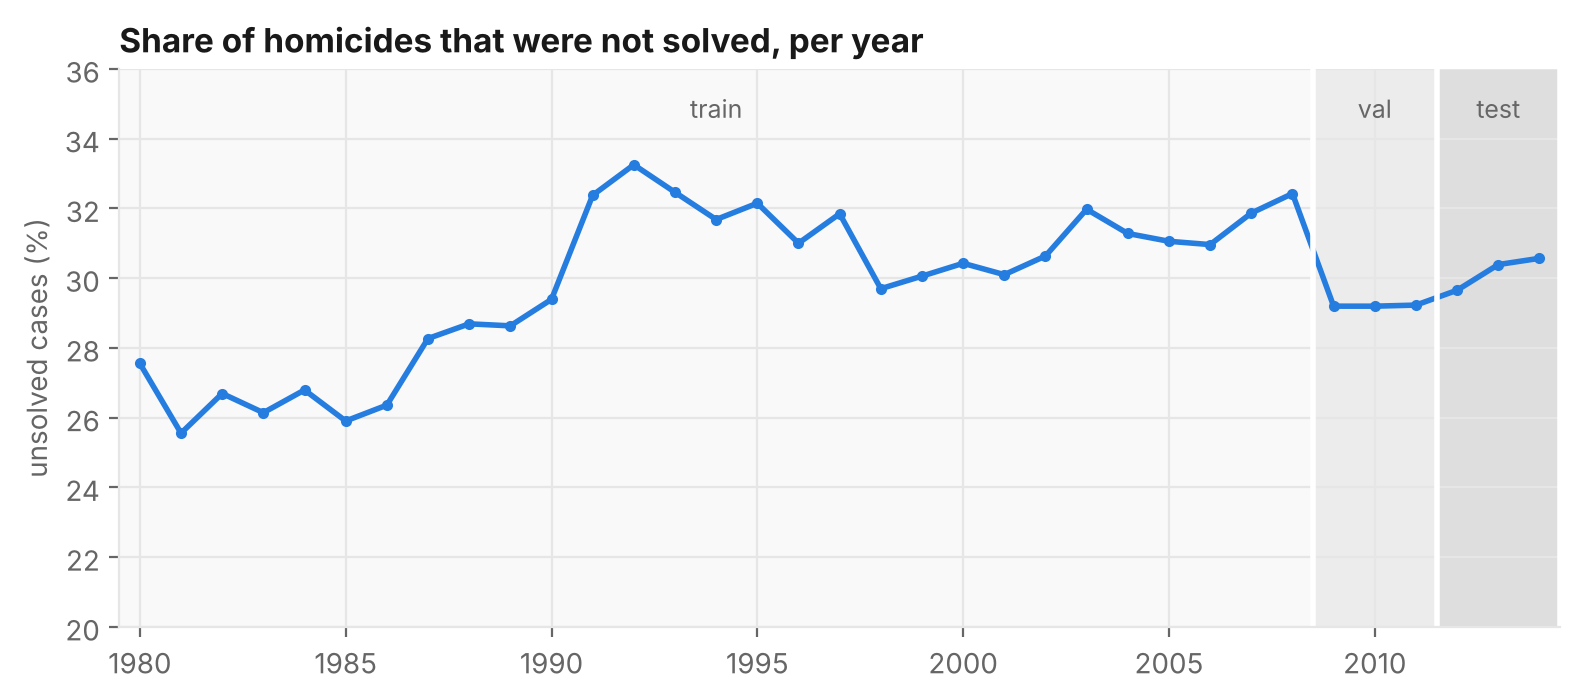

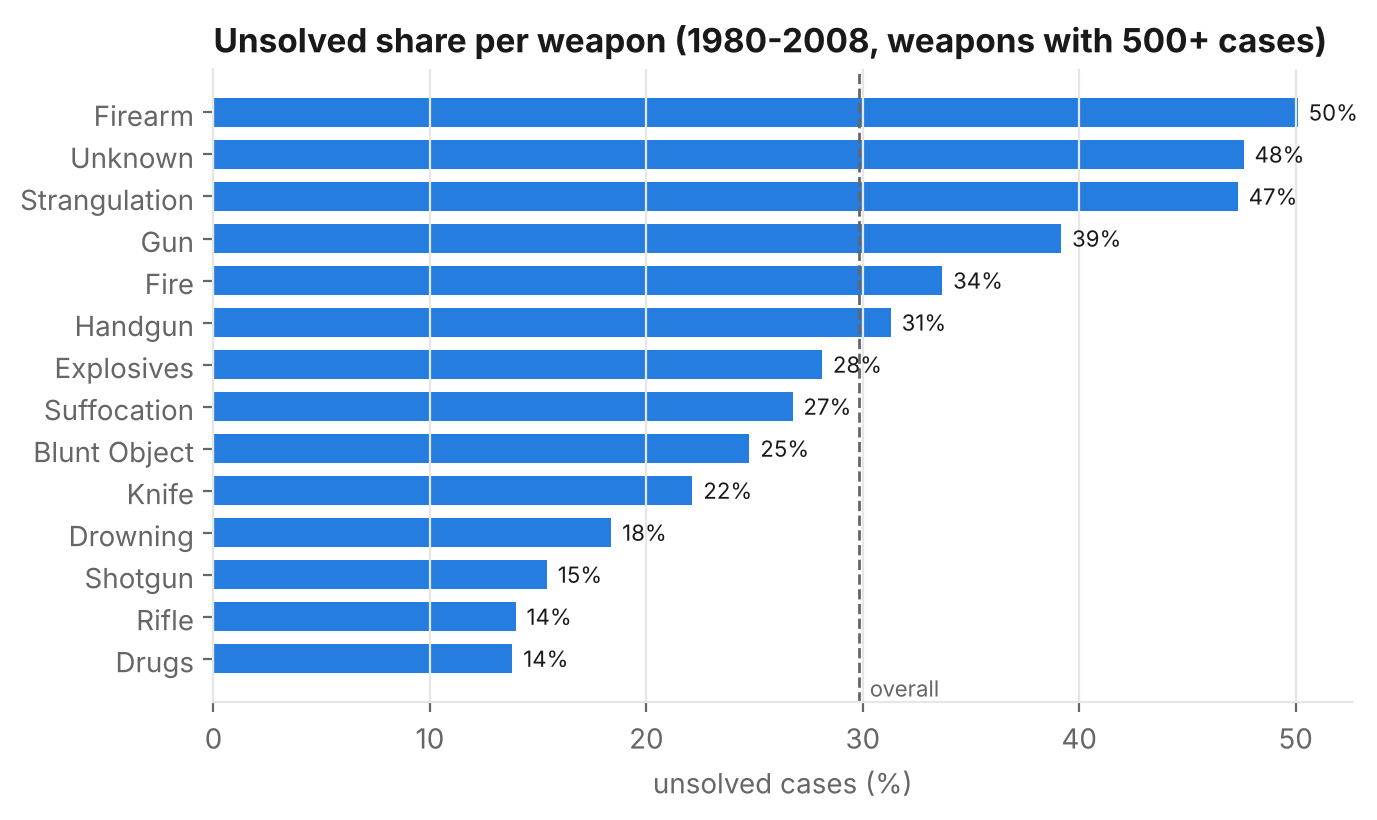

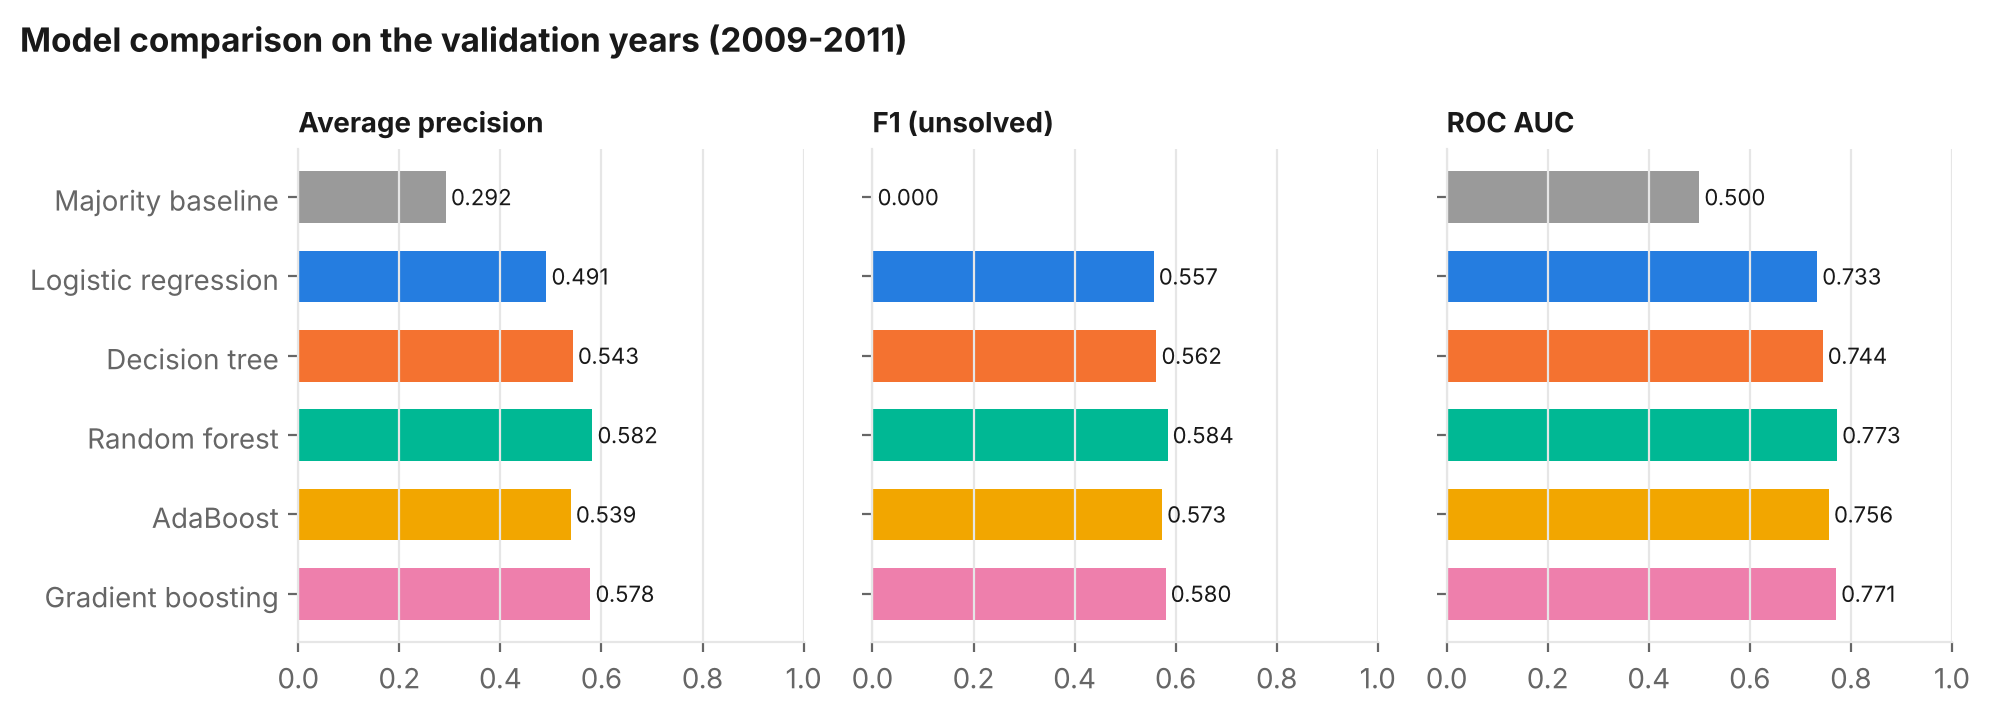

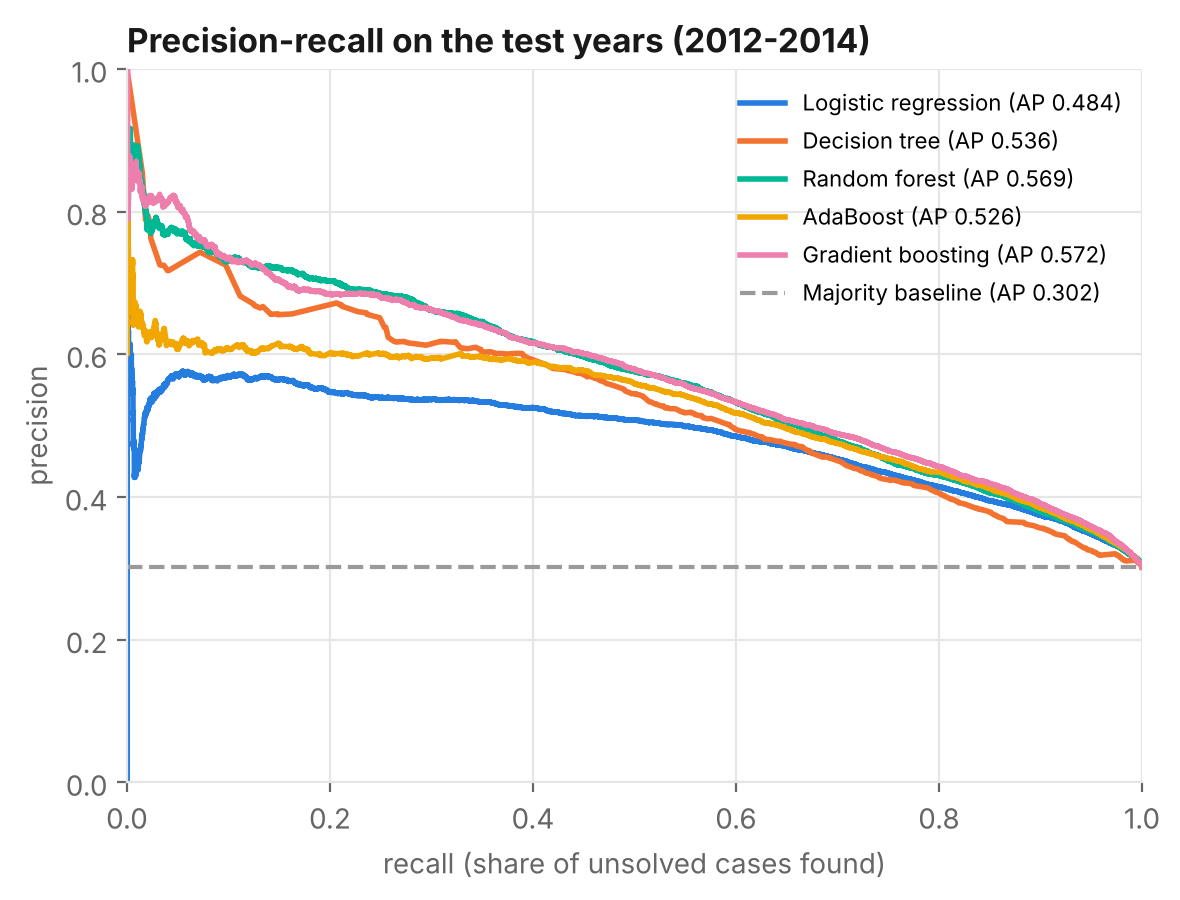

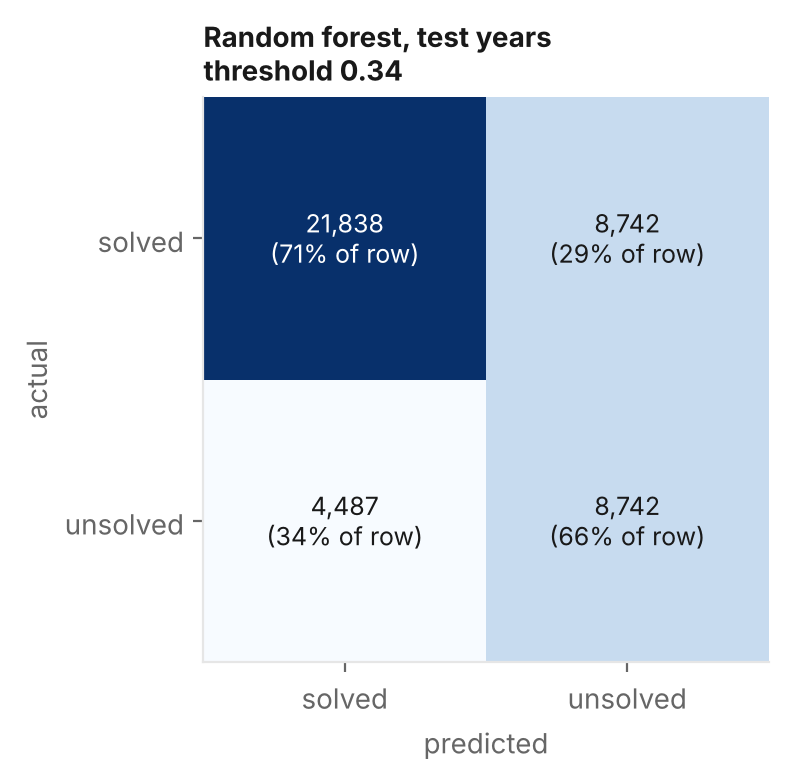

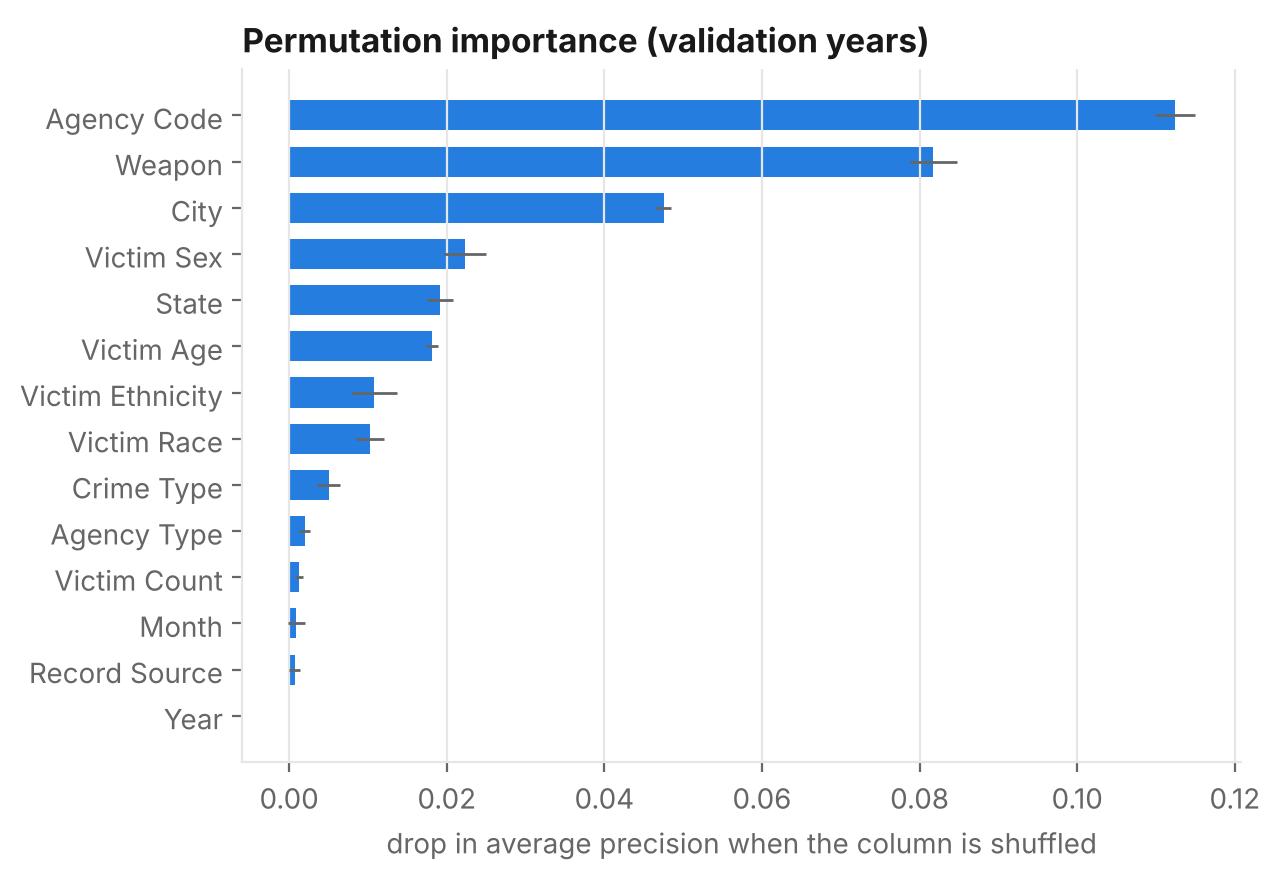

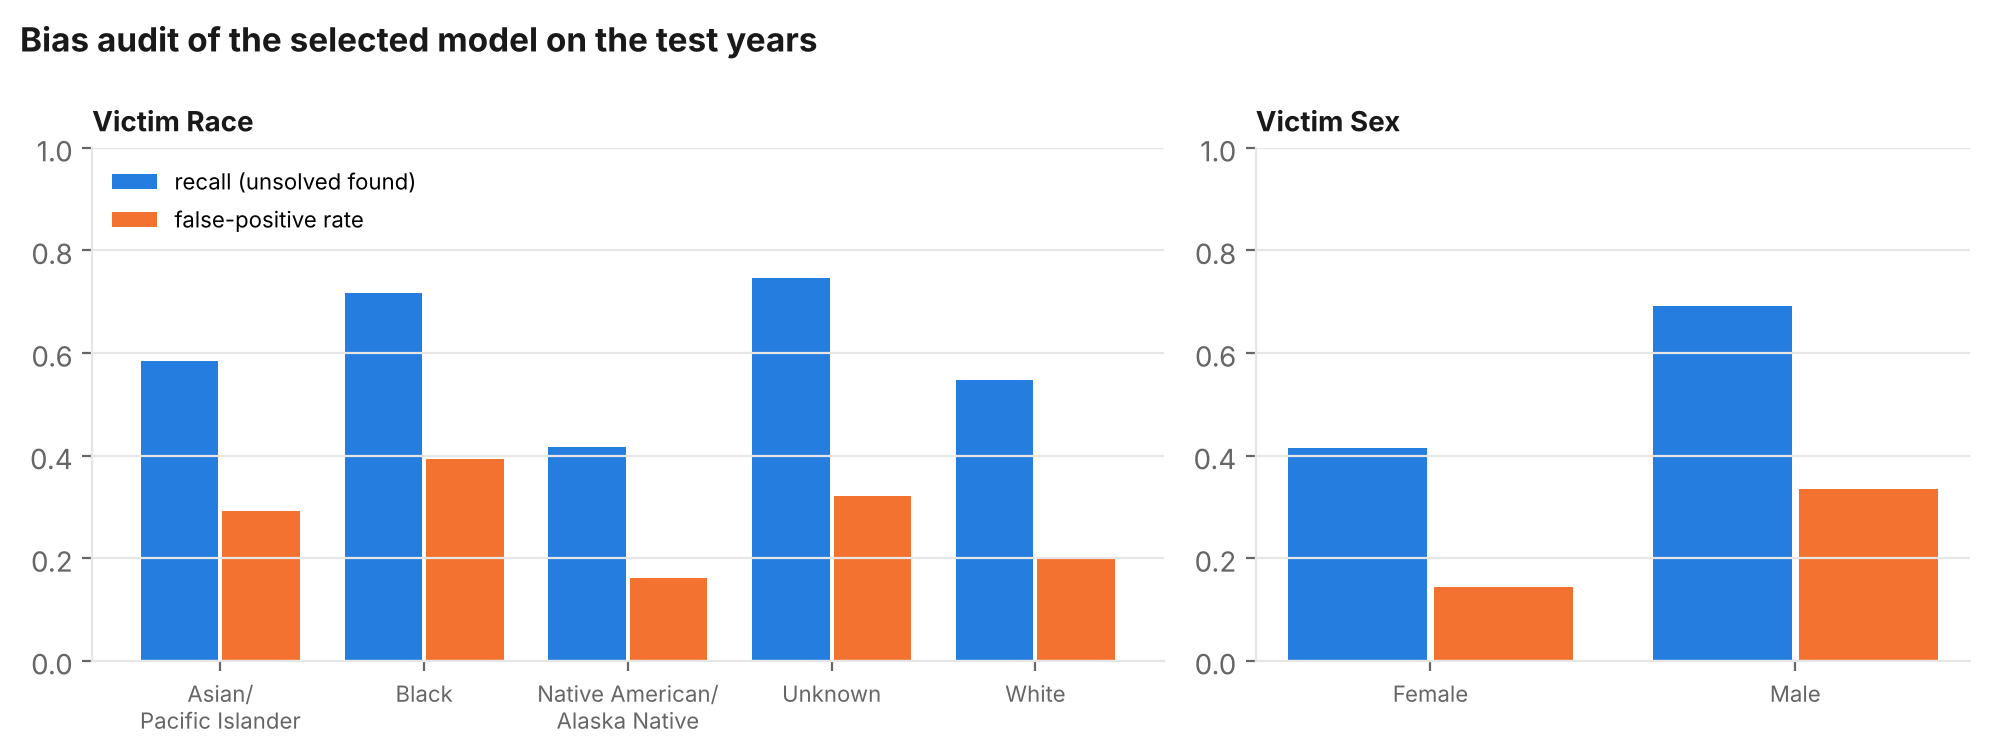

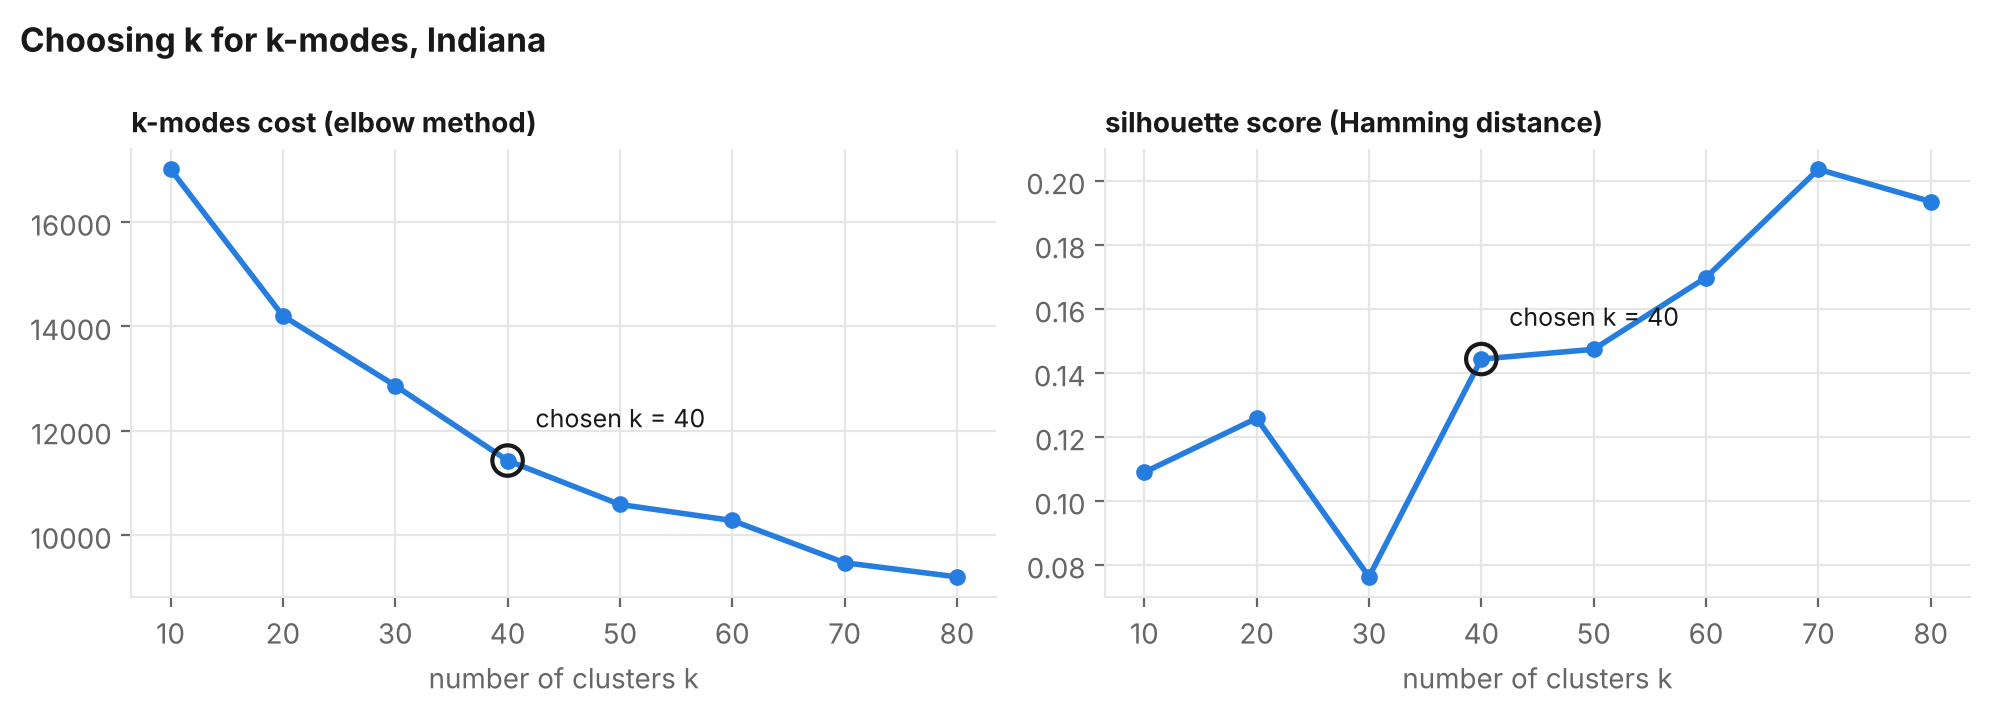

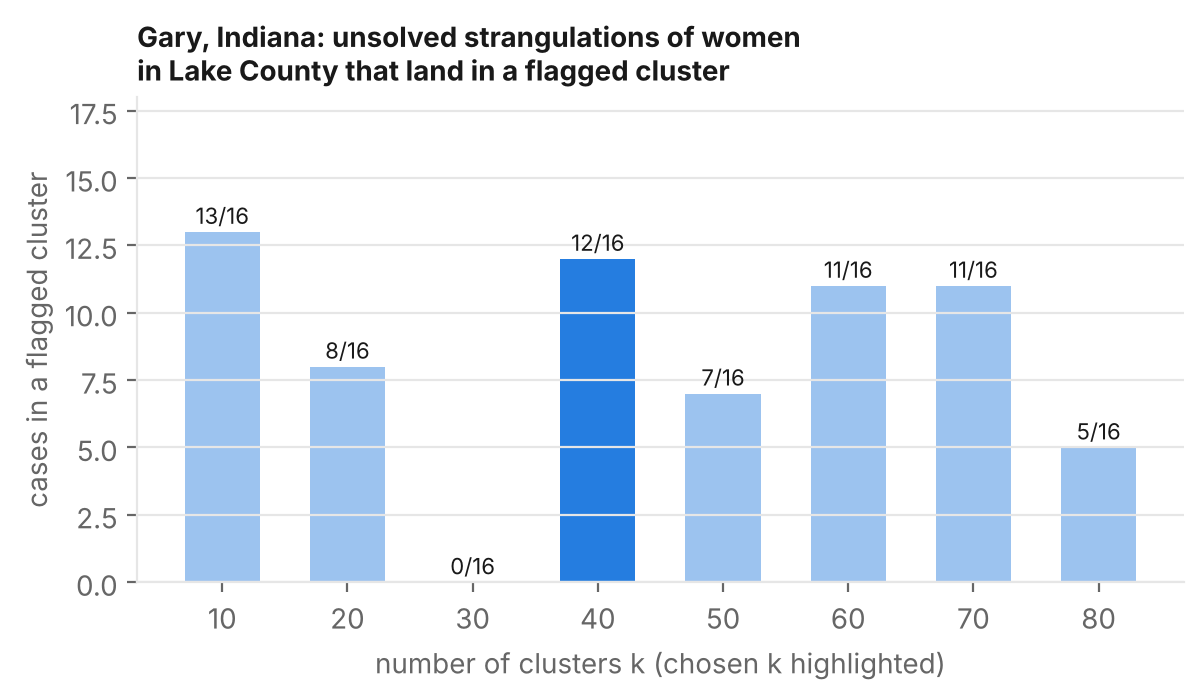

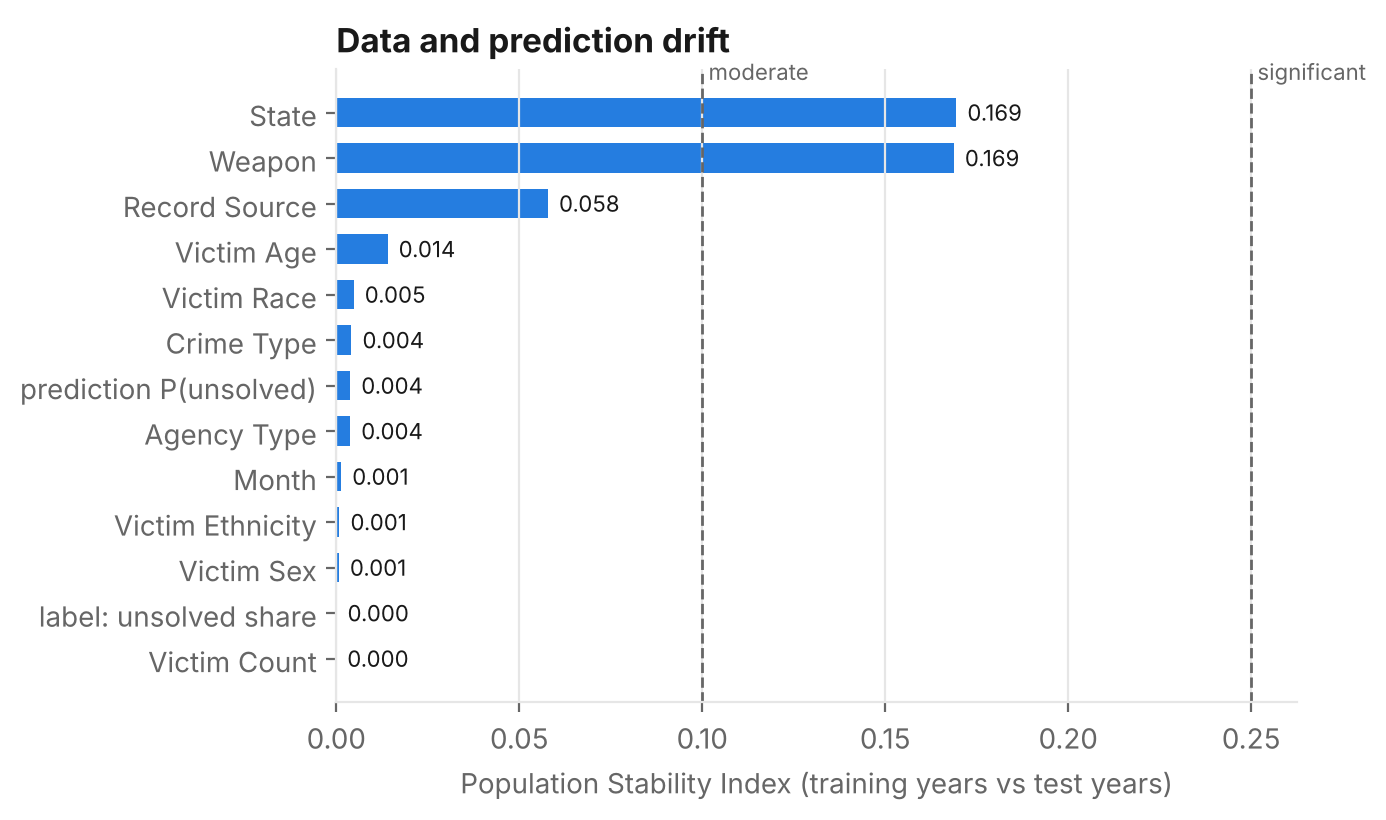

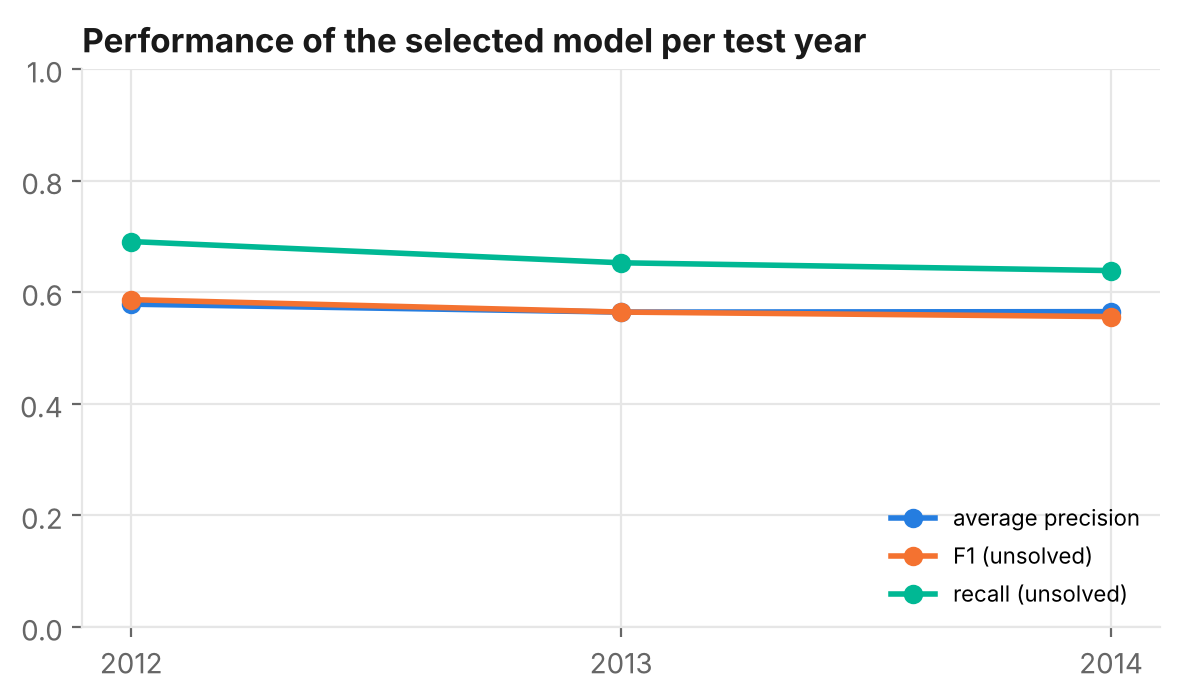

In [7]:
figures.run(cfg)
for f in sorted(FIG.glob('fig*.png')):
    display(Image(filename=str(f)))

## 6. Bias audit and error examples

In [8]:
pd.read_csv(MET / 'bias_audit.csv').round(3)

,attribute,group,n,unsolved_share,flag_rate,recall,precision,false_positive_rate
0,Victim Race,Asian/Pacific Islander,747,0.229,0.359,0.585,0.373,0.292
1,Victim Race,Black,21811,0.395,0.521,0.717,0.544,0.393
2,Victim Race,Native American/Alaska Native,315,0.152,0.200,0.417,0.317,0.161
3,Victim Race,Unknown,486,0.342,0.467,0.747,0.546,0.322
4,Victim Race,White,20450,0.207,0.272,0.548,0.417,0.200
5,Victim Sex,Female,9416,0.160,0.187,0.415,0.356,0.143
6,Victim Sex,Male,34314,0.340,0.457,0.692,0.516,0.335


In [9]:
pd.read_csv(MET / 'error_examples.csv')

,error,p_unsolved,Year,State,City,Agency Type,Victim Sex,Victim Age,Victim Race,Weapon,Crime Solved
0,missed unsolved case,0.025154,2012,Virginia,Newport News,Municipal Police,Male,0.0,Black,Blunt Object,No
1,missed unsolved case,0.025887,2013,Michigan,Bay,Sheriff,Female,48.0,White,Handgun,No
2,missed unsolved case,0.028980,2013,Utah,Utah,Municipal Police,Male,2.0,White,Blunt Object,No
3,missed unsolved case,0.029497,2013,North Carolina,McDowell,Sheriff,Male,16.0,White,Handgun,No
4,missed unsolved case,0.029850,2013,North Carolina,McDowell,Sheriff,Male,18.0,White,Handgun,No
5,missed unsolved case,0.030148,2012,North Carolina,Catawba,Sheriff,Female,44.0,White,Shotgun,No
6,missed unsolved case,0.030152,2013,Arkansas,Washington,Municipal Police,Male,0.0,White,Blunt Object,No
7,missed unsolved case,0.031672,2013,Arkansas,Cross,Municipal Police,Female,29.0,White,Handgun,No
8,missed unsolved case,0.032888,2014,Pennsylvania,Westmoreland,Municipal Police,Female,37.0,White,Handgun,No
9,missed unsolved case,0.033204,2013,Minnesota,Stearns,Sheriff,Female,1.0,White,Blunt Object,No


## 7. Demo: score new cases

In [10]:
from homicide.predict import SolvabilityModel
model = SolvabilityModel(cfg['paths']['models_dir'] / 'best_model.joblib')
model.predict(pd.read_csv(ROOT / 'examples' / 'sample_input.csv', dtype={'Agency Code': str}))

,Agency Code,Agency Type,City,State,Year,Month,Crime Type,Victim Sex,Victim Age,Victim Race,Victim Ethnicity,Weapon,Victim Count,Record Source,p_unsolved,p_solved,likely_to_go_cold
0,NY04601,Municipal Police,Schenectady,New York,2014,December,Murder or Manslaughter,Female,30,Black,Not Hispanic,Firearm,0,FBI,0.4869,0.5131,True
1,DE00206,Municipal Police,New Castle,Delaware,2014,August,Murder or Manslaughter,Male,34,Black,Unknown,Firearm,0,FBI,0.3992,0.6008,True
2,CA05606,Municipal Police,Ventura,California,2014,March,Murder or Manslaughter,Female,39,White,Hispanic,Handgun,0,FBI,0.2266,0.7734,False
3,AZ00713,Municipal Police,Maricopa,Arizona,2014,November,Murder or Manslaughter,Male,41,White,Not Hispanic,Handgun,0,FBI,0.2446,0.7554,False
4,NC09200,Sheriff,Wake,North Carolina,2014,April,Murder or Manslaughter,Female,57,Black,Unknown,Handgun,2,FBI,0.1857,0.8143,False
5,NC00401,Municipal Police,Anson,North Carolina,2014,March,Murder or Manslaughter,Female,45,Black,Unknown,Handgun,1,FBI,0.0762,0.9238,False
6,ILCPD00,Municipal Police,Cook,Illinois,2014,October,Murder or Manslaughter,Male,34,Black,Unknown,Handgun,0,FBI,0.6641,0.3359,True
7,FL00500,Sheriff,Brevard,Florida,2014,December,Murder or Manslaughter,Male,26,Black,Unknown,Firearm,0,FOIA,0.2889,0.7111,False
